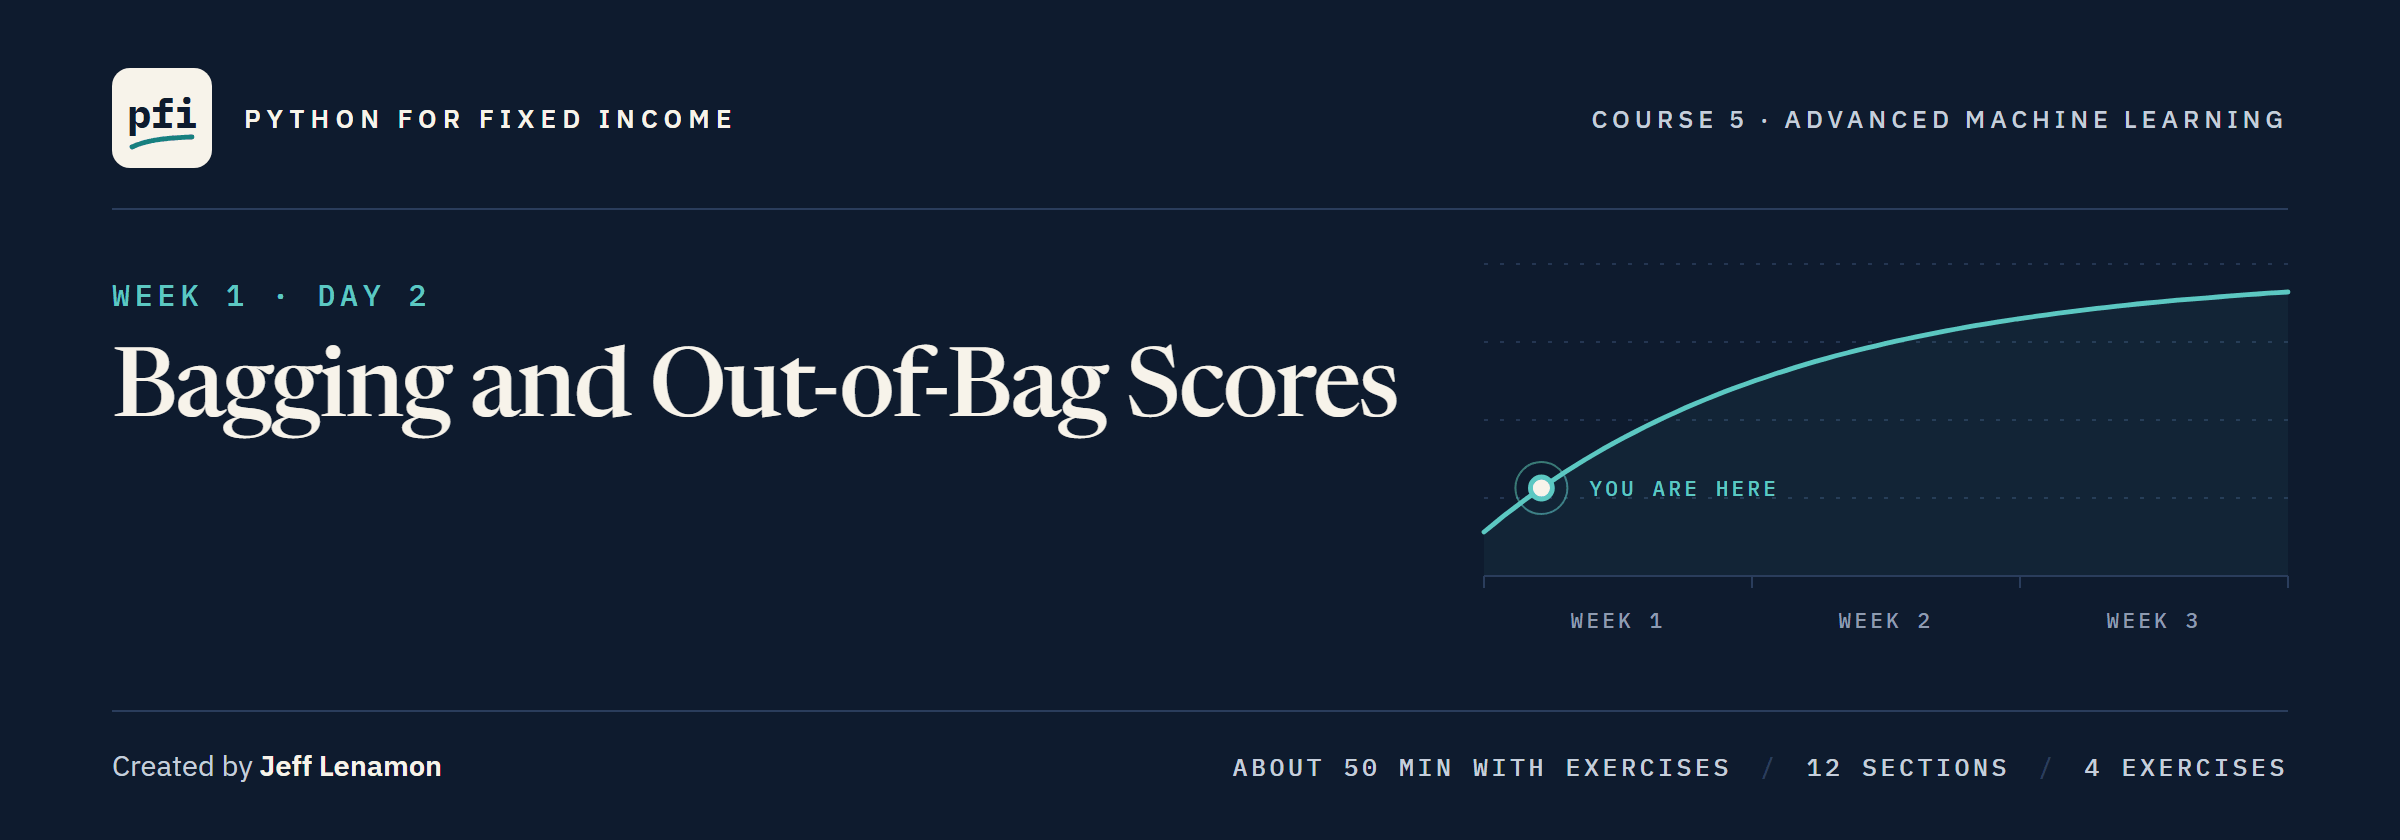

# Bagging and Out-of-Bag Scores

Week 1, Day 2. Let scikit-learn bag hundreds of trees, watch the bag settle as members are added, and score it on the rows each member never saw.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day2/02_bagging_and_out_of_bag_scores.ipynb)

# Problem Statement

## Business Context

Day 1 averaged ten full trees by hand and reached a validation ROC AUC of 0.7352, short of Course 4's 12-leaf pruned tree at 0.7627.
The desk now wants hundreds of trees, and a rule for setting them.
Course 4 chose its settings on the 6,000 validation rows; Course 5 chooses nothing on them.
So every choice needs a score made inside the 18,000 training rows that does not flatter the model, and a bag of trees carries one for free.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Fit a bagged model with scikit-learn and check it against an average you take yourself, and watch an account's output and the bag's score settle as members are added.
Score a bag on its own out-of-bag rows, read every number it reports, compare an out-of-bag score with five-fold cross-validation, choose a setting out of bag and report it on validation rows, and bag a model other than a tree.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

## Your Route Through Day 2

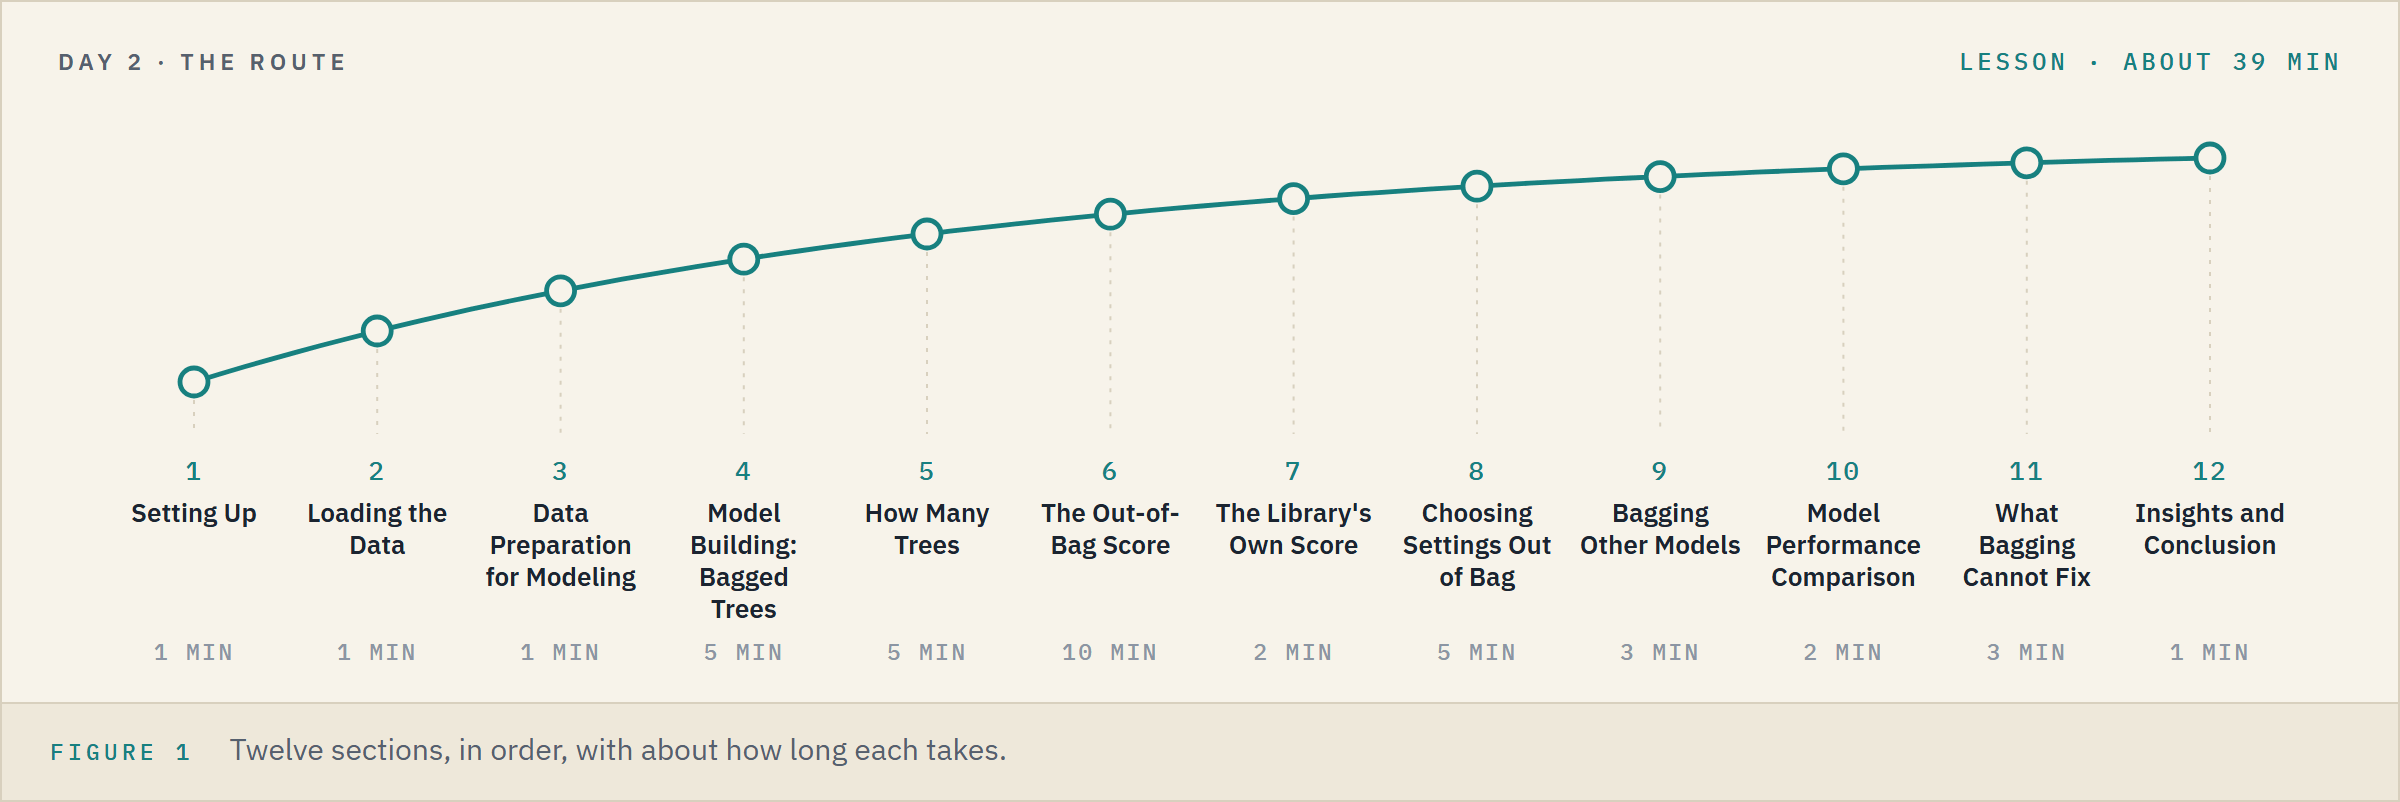

**Time.** About 39 minutes for the lesson, then about 12 for the four exercises.

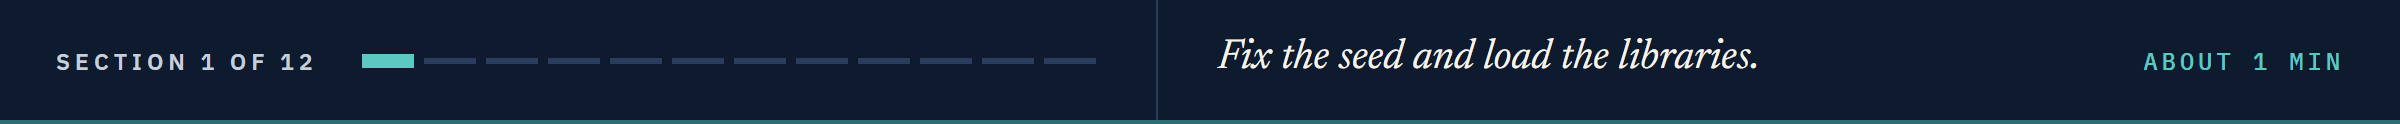

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, a slider, and the binomial law
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact
from scipy import stats

# to split the accounts, and to cross-validate
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# the models: trees, bags of models, and Course 4's logistic pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# to score a model's outputs and its flags
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import confusion_matrix

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Course 4's colour for each of the four cells of a confusion matrix
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

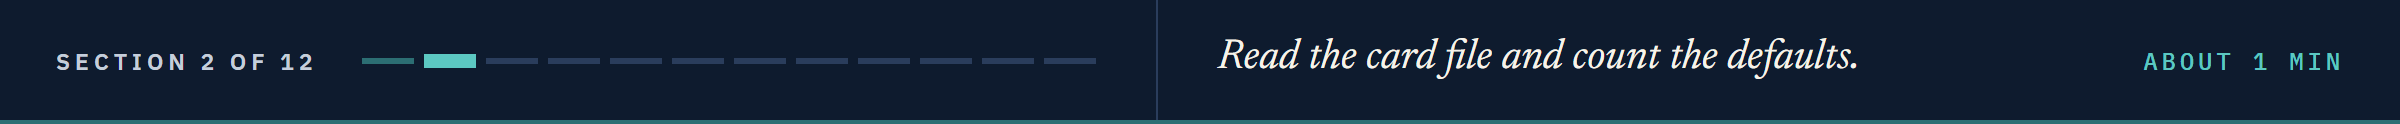

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we rebuild its rows exactly.**

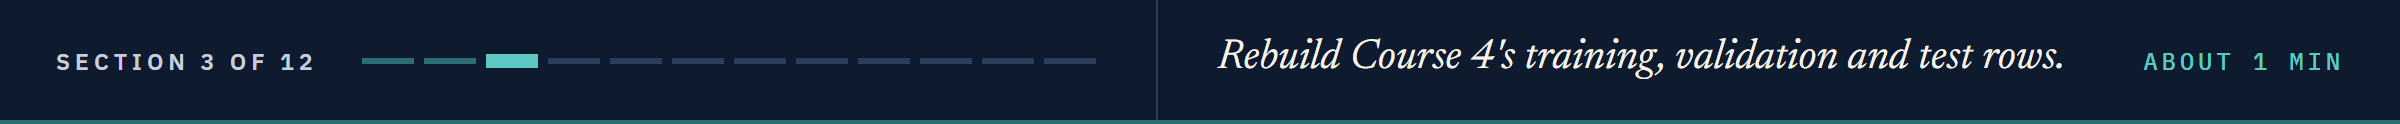

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


The same 18,000, 6,000 and 6,000 accounts as Course 4, each with the same default share.

Course 4 used the validation rows to choose settings; Course 5 only reports on them, and never scores the test rows.

**Training rows fit, validation rows report, test rows stay closed.**

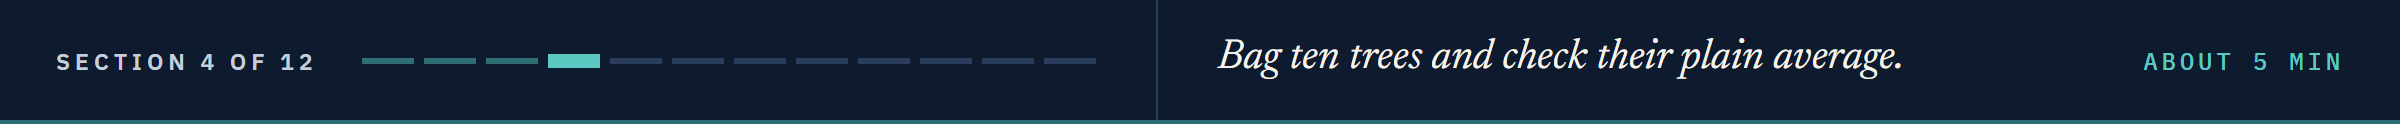

# Model Building: Bagged Trees

## Course 4's Models to Beat

In [6]:
# Course 4's models on the same rows: the full tree, Day 9's pruned tree, Day 6's logistic pipeline
full_tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
pruned_tree = DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED).fit(X_train, y_train)
logit = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)

# their ROC AUC on the validation rows
pruned_auc = roc_auc_score(y_valid, pruned_tree.predict_proba(X_valid)[:, 1])
logit_auc = roc_auc_score(y_valid, logit.predict_proba(X_valid)[:, 1])
print("Full tree:", round(roc_auc_score(y_valid, full_tree.predict_proba(X_valid)[:, 1]), 4),
      " Pruned tree:", round(pruned_auc, 4), " Logistic:", round(logit_auc, 4))

Full tree: 0.6161  Pruned tree: 0.7627  Logistic: 0.719


## Ten Trees in One Call

`BaggingClassifier` does Day 1's work in one call: it draws `n_estimators` bootstrap samples, fits a copy of `estimator` on each, and averages their outputs.
A **member** is one model inside an ensemble.
`n_jobs=1` fits one member at a time, the course's rule for anything that can run in parallel.

In [7]:
# ten full trees, each fitted on its own bootstrap sample of the training rows, their outputs averaged
bag10 = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=10,
                          random_state=SEED, n_jobs=1).fit(X_train, y_train)
valid10 = bag10.predict_proba(X_valid)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_valid, valid10), 4),
      " Average precision:", round(average_precision_score(y_valid, valid10), 4))

ROC AUC: 0.732  Average precision: 0.4584


Day 1's ten samples, averaged by hand, scored 0.7352.

scikit-learn draws its own ten samples from the seed, so the same recipe lands a few thousandths away.

## Is It the Average of Its Members?

`.estimators_` holds the fitted members.
Each was fitted on a plain array, without column names, so we ask it about `X_valid.to_numpy()`.
`np.column_stack` sets arrays side by side as the columns of one table.
`.estimators_samples_` holds each member's bootstrap sample as row positions.

In [8]:
# each member's output for every validation account, one column per member, then their plain average
members10 = np.column_stack([tree.predict_proba(X_valid.to_numpy())[:, 1] for tree in bag10.estimators_])
print(members10.shape)
print("Largest gap from the bag's own output:", np.abs(members10.mean(axis=1) - valid10).max())

# distinct training rows in each member's sample
print([len(np.unique(rows)) for rows in bag10.estimators_samples_])

(6000, 10)
Largest gap from the bag's own output: 2.220446049250313e-16
[11413, 11384, 11367, 11321, 11423, 11383, 11344, 11371, 11382, 11346]


The bag's output is the members' average to the last digit.

Each member saw 11,321 to 11,423 distinct accounts, about 63 percent of the training rows, as on Day 1.

**A bagged probability is the plain average of its members, nothing more.**

## Training Against Validation

Course 4's Day 8 scoring function, repeated: ROC AUC, then Day 7's four measures at a threshold.

In [9]:
# flag at or above the threshold, then ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [10]:
# the ten-tree bag on the rows it was fitted on, and on the validation rows
bag10_train_perf = model_performance_classification(bag10, X_train, y_train)
bag10_valid_perf = model_performance_classification(bag10, X_valid, y_valid)
train_valid = pd.concat([bag10_train_perf.T, bag10_valid_perf.T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
ROC AUC,0.9977,0.7320
Accuracy,0.9806,0.7943
Recall,0.9397,0.4069
Precision,0.9717,0.5471
F1,0.9554,0.4667


Course 4's Day 7 confusion matrix, repeated.

In [11]:
# draw a confusion matrix: each cell in its own colour, with its name, its count and its share of the accounts
def draw_confusion(target, flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(target, flags).ravel()  # .ravel() lays the 2 by 2 out flat: TN, FP, FN, TP
    total = tn + fp + fn + tp
    # :.1% writes a share as a percent with one decimal
    labels = [[f"TN\n{tn:,}\n{tn / total:.1%}", f"FP\n{fp:,}\n{fp / total:.1%}"],
              [f"FN\n{fn:,}\n{fn / total:.1%}", f"TP\n{tp:,}\n{tp / total:.1%}"]]
    # the numbers 0 to 3 pick each cell's colour from the list; annot writes the labels on top (fmt="" as they are), annot_kws sets their size
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged (0)", "flagged (1)"], yticklabels=["paid (0)", "defaulted (1)"])
    ax.set(xlabel="The flag", ylabel="What happened", title=title)  # ax.set sets several of the chart's labels in one call

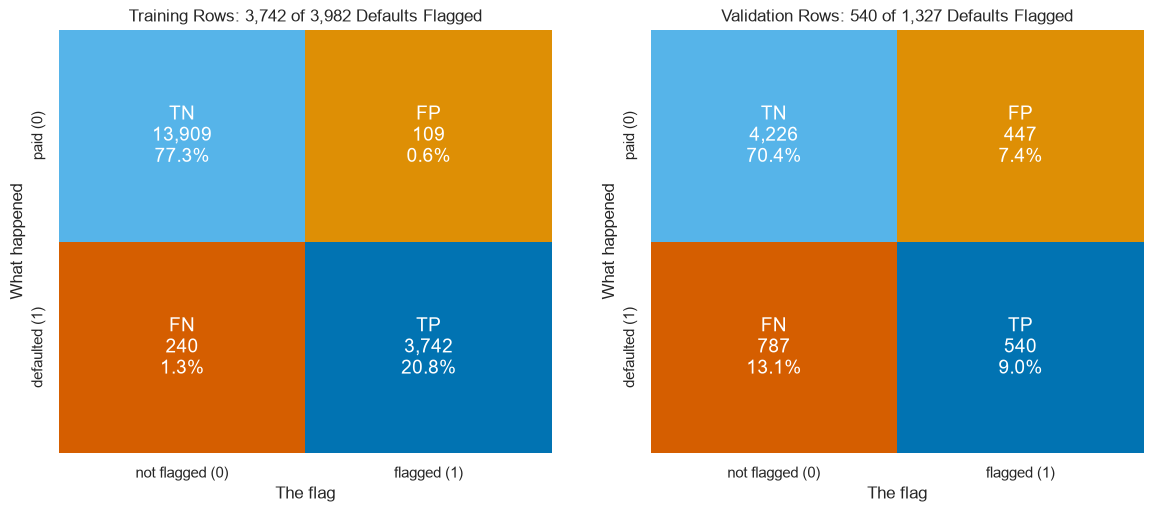

In [12]:
# the ten-tree bag's flags at 0.5 on the training rows beside the validation rows
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
draw_confusion(y_train, (bag10.predict_proba(X_train)[:, 1] >= 0.5).astype(int), left, "Training Rows: 3,742 of 3,982 Defaults Flagged")
draw_confusion(y_valid, (valid10 >= 0.5).astype(int), right, "Validation Rows: 540 of 1,327 Defaults Flagged")
plt.show()

ROC AUC 0.9977 on the training rows and 0.7320 on the validation rows.

Recall falls from 0.9397 to 0.4069: the bag flags almost every training default and fewer than half of the new ones.

Each member saw about 63 percent of the training rows, and a full tree hands its own rows back, so the training rows flatter the bag.

**Training rows flatter a bag. First see how many members it needs.**

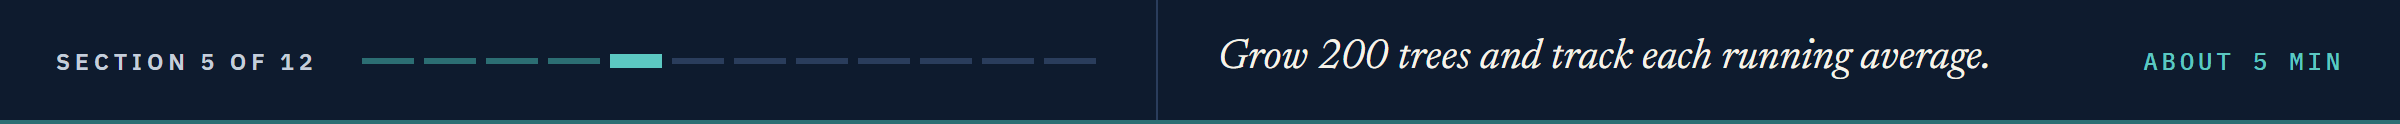

# How Many Trees

## Two Hundred Trees, One Fit

`oob_score=True` makes the bag keep a second set of outputs while it fits; we open them in a later section.

In [13]:
# 200 full trees in one bag
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=200, oob_score=True,
                        random_state=SEED, n_jobs=1).fit(X_train, y_train)

# the same seed draws the same samples first: are the bag's first ten samples the ten-tree bag's?
print(all([np.array_equal(a, b) for a, b in zip(bag.estimators_samples_[:10], bag10.estimators_samples_)]))

True


The first ten members of `bag` are the ten-tree bag.

So one fit of 200 holds every smaller bag: the first k members.

## Each Account's Average as Members Are Added

A **running average** is the average of the first k members, for every k at once.
`.cumsum(axis=1)` adds along each row, and dividing by the counts 1 to 200 turns each sum into an average.

In [14]:
# the 200 members' outputs for every validation account: one row per account, one column per member
outputs = np.column_stack([tree.predict_proba(X_valid.to_numpy())[:, 1] for tree in bag.estimators_])

# the running average: for each account, the average of the first k members, for k = 1 to 200
trees = np.arange(1, 201)
running = outputs.cumsum(axis=1) / trees
print(outputs.shape, running.shape)

(6000, 200) (6000, 200)


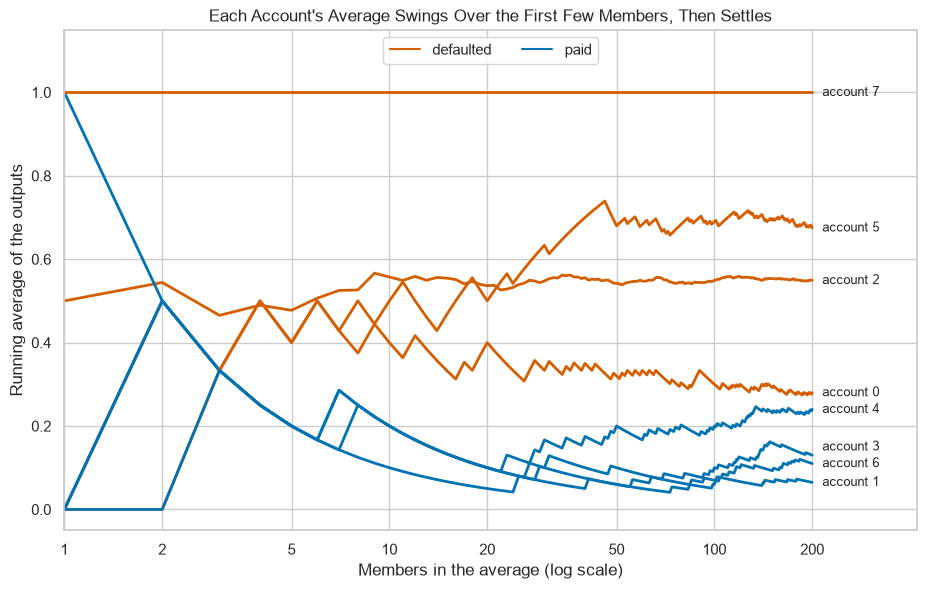

In [15]:
# the running average of the first eight validation accounts, red where the account defaulted, on a log axis
fig, ax = plt.subplots(figsize=(11, 6.5))
label_y = running[:8, -1].copy()
label_y[3] += 0.02  # accounts 3 and 6 end close together: lift one label so the two do not touch
for account in range(8):
    ax.plot(trees, running[account], color="C3" if y_valid.iloc[account] == 1 else "C0", linewidth=2)
    ax.text(215, label_y[account], "account " + str(account), va="center", fontsize=9)
# two empty lines, drawn only to put the two colours in the legend
ax.plot([], [], color="C3", label="defaulted")
ax.plot([], [], color="C0", label="paid")
ax.set_xscale("log")
ax.set(xticks=[1, 2, 5, 10, 20, 50, 100, 200], xticklabels=[1, 2, 5, 10, 20, 50, 100, 200])  # plain numbers on the log axis
ax.set(xlim=(1, 420), ylim=(-0.05, 1.15), xlabel="Members in the average (log scale)", ylabel="Running average of the outputs")
ax.set_title("Each Account's Average Swings Over the First Few Members, Then Settles")
ax.legend(loc="upper center", ncol=2)
plt.show()

`np.diff(..., axis=1)` takes the difference between neighbours along each row: how far the k-th member moves an account's average.

In [16]:
# how far one more member moves an account's average, averaged over the accounts
moves = np.abs(np.diff(running, axis=1)).mean(axis=0)
print("Mean move at the 2nd, 10th, 100th and 200th member:", moves[[0, 8, 98, 198]].round(4))

# accounts whose flag at 0.5 changes between the 100-member and the 200-member average
print("Flags that change from 100 to 200 members:", ((running[:, 99] >= 0.5) != (running[:, 199] >= 0.5)).sum())

Mean move at the 2nd, 10th, 100th and 200th member: [0.1309 0.0263 0.0027 0.0013]
Flags that change from 100 to 200 members: 51


Every trace swings over the first few members, then flattens.

Account 4 paid: its first member said 1.0, and its average settles near 0.24.

Account 7 defaulted, and every member says 1.0.

One more member moves an account less and less, in step with one over the count of members: 0.13 at the second, 0.026 at the 10th, 0.0013 at the 200th.

51 accounts still change flag between 100 and 200 members.

**Predict 1**

Ten members score 0.7320 on the validation rows.

Q. What does the average of all 200 score? Write down a number.

## The Score by Number of Trees

In [17]:
# validation ROC AUC of the running average at every count of members
curve = pd.Series([roc_auc_score(y_valid, running[:, k - 1]) for k in trees], index=trees)
print(curve[[1, 10, 25, 50, 100, 200]].round(4).to_dict())
print("Average precision at 200:", round(average_precision_score(y_valid, running[:, 199]), 4))

{1: 0.6077, 10: 0.732, 25: 0.7495, 50: 0.7594, 100: 0.7602, 200: 0.7621}
Average precision at 200: 0.511


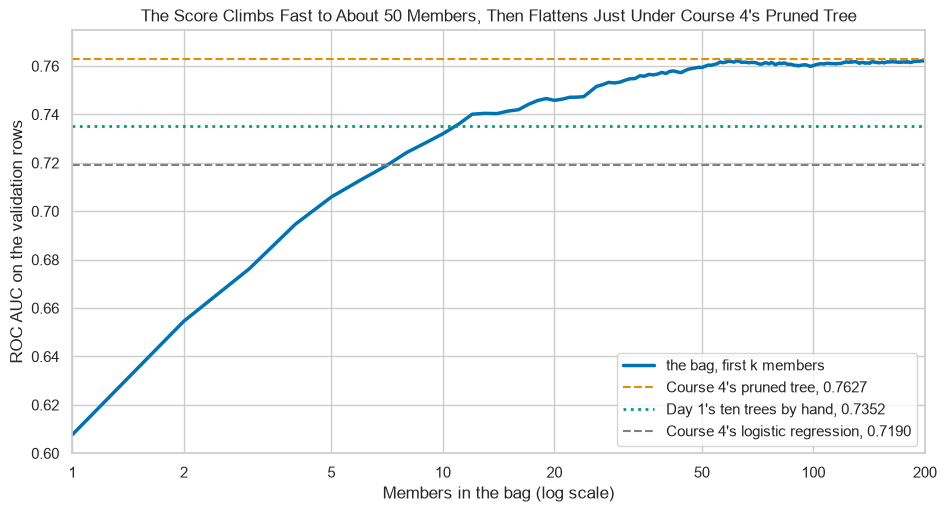

In [18]:
# the curve on a log axis, with Day 1's hand-made average and two of Course 4's models as lines
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(trees, curve, linewidth=2.5, label="the bag, first k members")
ax.axhline(pruned_auc, color="C1", linestyle="--", label=f"Course 4's pruned tree, {pruned_auc:.4f}")
ax.axhline(0.7352, color="C2", linestyle=":", linewidth=2, label="Day 1's ten trees by hand, 0.7352")
ax.axhline(logit_auc, color="gray", linestyle="--", label=f"Course 4's logistic regression, {logit_auc:.4f}")
ax.set_xscale("log")
ax.set(xticks=[1, 2, 5, 10, 20, 50, 100, 200], xticklabels=[1, 2, 5, 10, 20, 50, 100, 200])
ax.set(xlim=(1, 200), ylim=(0.6, 0.775), xlabel="Members in the bag (log scale)", ylabel="ROC AUC on the validation rows")
ax.set_title("The Score Climbs Fast to About 50 Members, Then Flattens Just Under Course 4's Pruned Tree")
ax.legend(loc="lower right")
plt.show()

One full tree scores 0.6077; 25 members 0.7495, 50 members 0.7594, 200 members 0.7621.

Past about 50 members the curve is nearly flat.

200 full trees still sit just under Course 4's 12-leaf pruned tree.

**Fifty trees do most of the work, and full trees stall just under Course 4's tree. Settings might pass it, but Course 5 may not choose them on validation rows.**

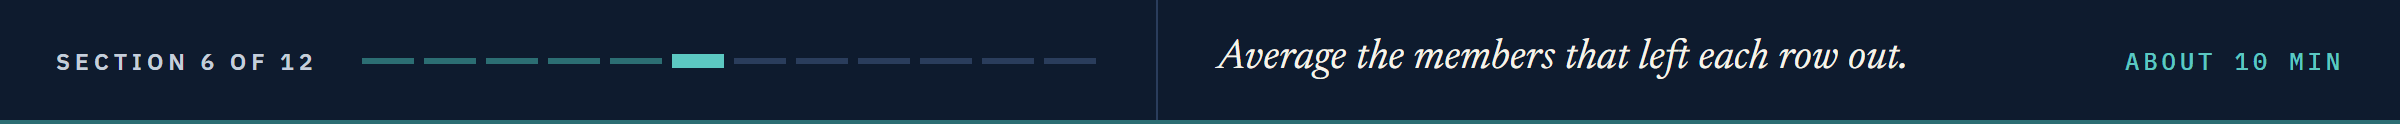

# The Out-of-Bag Score

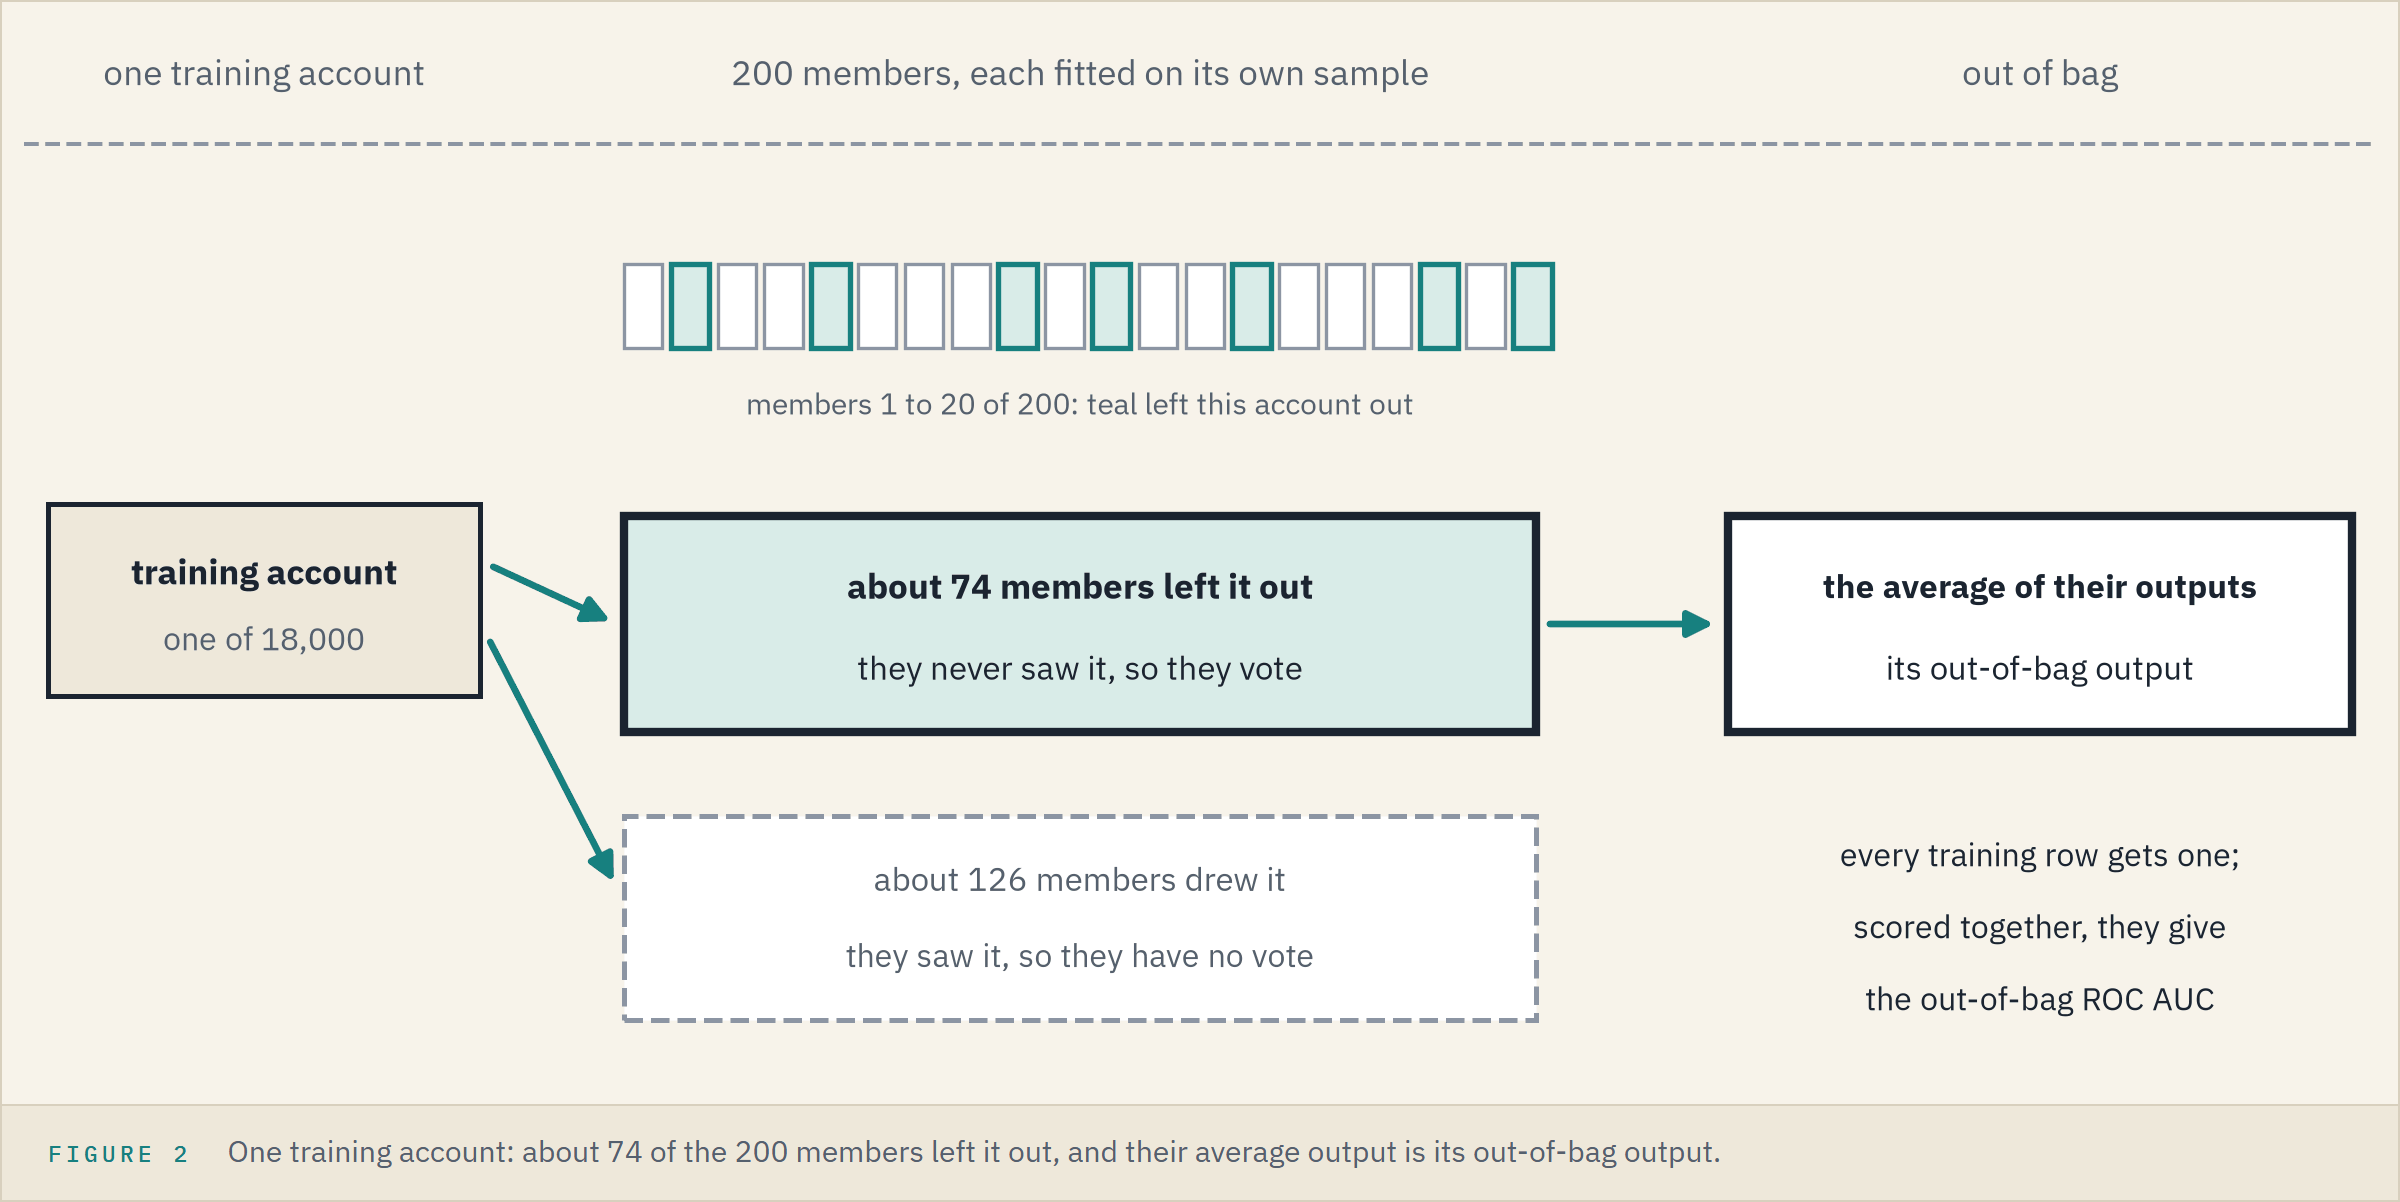

Day 1 scored each tree on the rows its sample never drew.
A bag does the same for every training row at once.
A row's **out-of-bag output** is the average of only the members whose samples left it out.
Scored over all 18,000 training rows, those outputs give the bag's **out-of-bag ROC AUC**.

## Which Members Left Each Row Out

`left_out[rows, j] = False` sets every position a member drew to False in its column, repeats and all.

In [19]:
# one row per training account, one column per member: True where the member's sample left the account out
left_out = np.ones((len(X_train), 200), dtype=bool)
for j, rows in enumerate(bag.estimators_samples_):
    left_out[rows, j] = False
print(left_out.shape, " Share left out:", round(left_out.mean(), 4))

# the 200 members' outputs for every training account, as for the validation accounts
train_outputs = np.column_stack([tree.predict_proba(X_train.to_numpy())[:, 1] for tree in bag.estimators_])

(18000, 200)  Share left out: 0.3676


### Your Turn: Grow the Bag

The chart shows 24 training accounts and the first k members: green where the member left the account out.
Beside each account is its out-of-bag output so far, red if it defaulted and blue if it paid.

In [20]:
# for 24 training accounts: who left each out among the first k members, and the out-of-bag output so far
def draw_votes(k=10):
    votes = left_out[:24, :k]
    voted = votes.sum(axis=1)
    so_far = (train_outputs[:24, :k] * votes).sum(axis=1) / np.maximum(voted, 1)  # np.maximum: never divide by 0
    fig, (grid, side) = plt.subplots(1, 2, figsize=(12, 6), width_ratios=[4, 1], sharey=True)
    sns.heatmap(votes.astype(int), cmap=["lightgray", "#029E73"], vmin=0, vmax=1, cbar=False, xticklabels=False, ax=grid)
    for row in range(24):
        if voted[row] == 0:
            side.text(0.03, row + 0.5, "no vote", va="center", color="gray")
        else:
            side.scatter(so_far[row], row + 0.5, s=70, color="C3" if y_train.iloc[row] == 1 else "C0")
    grid.set(xlabel=f"The first {k} members (green: left the account out)", ylabel="Training account")
    grid.tick_params(axis="y", rotation=0)
    side.set(xlim=(-0.05, 1.05), ylim=(24, 0), xlabel="Out-of-bag output so far")
    no_vote = (left_out[:, :k].sum(axis=1) == 0).sum()
    fig.suptitle(f"{k} Members: {no_vote:,} of 18,000 Training Rows Have No Out-of-Bag Vote Yet")
    plt.show()

In [21]:
# your turn: slide k and watch the green cells fill in and the rows with no vote disappear
interact(draw_votes, k=(1, 200));

interactive(children=(IntSlider(value=10, description='k', max=200, min=1), Output()), _dom_classes=('widget-i…

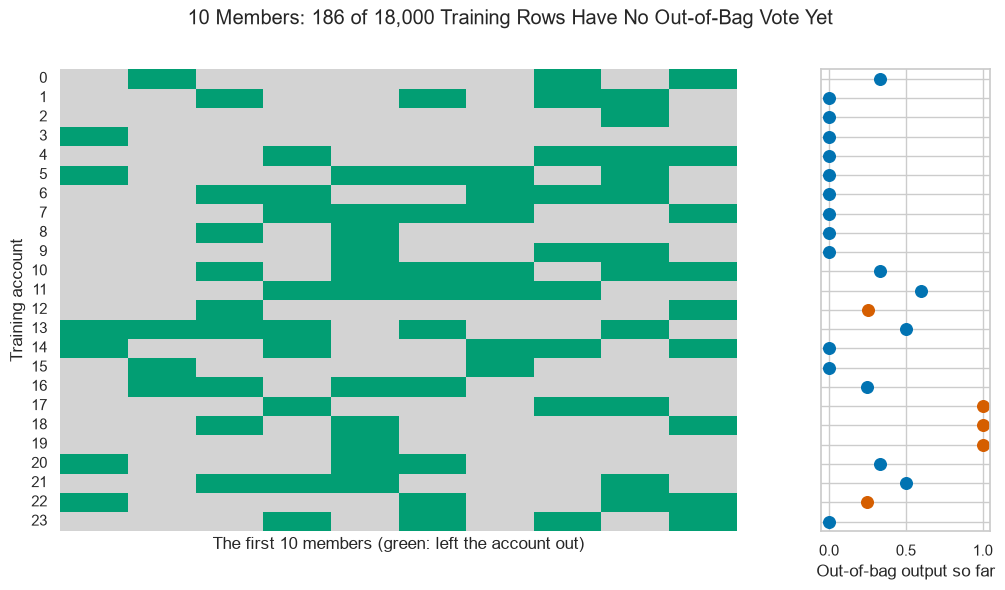

In [22]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_votes(10)

In [23]:
# training rows with no out-of-bag vote after the first k members
no_vote = (left_out.cumsum(axis=1) == 0).sum(axis=0)
print({k: int(no_vote[k - 1]) for k in [1, 2, 5, 10, 20, 21]})

{1: 11413, 2: 7226, 5: 1822, 10: 186, 20: 1, 21: 0}


After one member, every row its sample drew has no vote.

After 10 members, 186 rows still have none; from 21 members on, every row has a vote.

scikit-learn warns when a row has no vote, so every bag scored out of bag here has 25 members or more.

## How Many Members Vote on Each Row

Each member leaves a row out with Day 1's chance, (1 - 1/n)^n, about 0.368, and the 200 samples are drawn independently.
The count of members that leave a row out then follows the **binomial law**.
`stats.binom.pmf(k, 200, p)` is its chance of exactly k, and `stats.binom.std(200, p)` its standard deviation.

In [24]:
# how many members left each training row out, against the binomial law
voters = left_out.sum(axis=1)
p_out = (1 - 1 / len(X_train)) ** len(X_train)
print("Mean:", round(voters.mean(), 2), " Fewest:", voters.min(), " Most:", voters.max())
print("Standard deviation:", round(voters.std(), 2), " By the law:", round(stats.binom.std(200, p_out), 2))

Mean: 73.53  Fewest: 45  Most: 100
Standard deviation: 6.81  By the law: 6.82


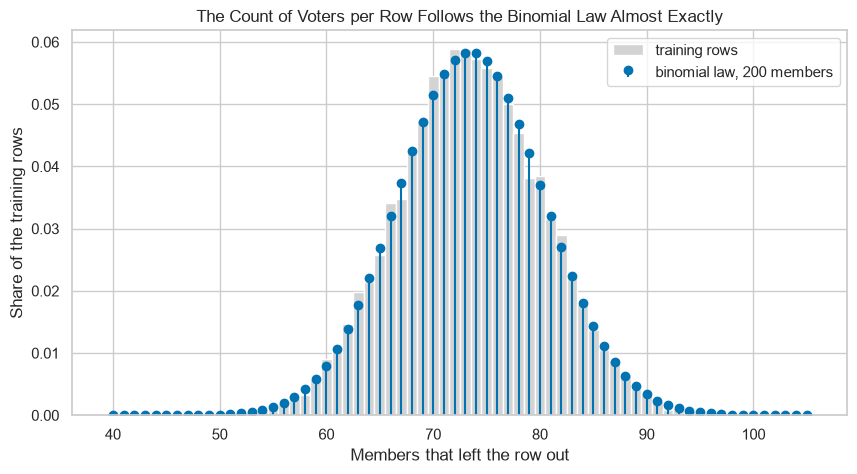

In [25]:
# the share of training rows with each count of voters (bars) against the binomial law's chances (stems)
counts = np.arange(40, 106)
shares = np.bincount(voters, minlength=201)[counts] / len(X_train)
fig, ax = plt.subplots()
ax.bar(counts, shares, width=1, color="lightgray", edgecolor="white", label="training rows")
ax.stem(counts, stats.binom.pmf(counts, 200, p_out), linefmt="C0-", markerfmt="C0o", basefmt=" ",
        label="binomial law, 200 members")  # ax.stem draws a line and a dot at each count
ax.set(xlabel="Members that left the row out", ylabel="Share of the training rows")
ax.set_title("The Count of Voters per Row Follows the Binomial Law Almost Exactly")
ax.legend()
plt.show()

About 74 of the 200 members vote on a typical row, and every row has at least 45.

The bars and the stems agree, and so do the two standard deviations.

## The Out-of-Bag Output by Hand

`.oob_decision_function_` holds the out-of-bag output scikit-learn kept when it fitted with `oob_score=True`: a row per training account, a column per class.

In [26]:
# each training row's out-of-bag output: the outputs of the members that left it out, averaged
oob_output = (train_outputs * left_out).sum(axis=1) / voters
print("Largest gap from scikit-learn's:", np.abs(oob_output - bag.oob_decision_function_[:, 1]).max())

Largest gap from scikit-learn's: 3.3306690738754696e-16


A gap of a few parts in ten thousand million million: the same numbers.

That average is all `oob_score=True` does.

**Predict 2**

The bag scores 0.7621 on the validation rows.

Q. What does its out-of-bag output score by ROC AUC on the training rows? Write down a number.

## The Out-of-Bag ROC AUC

In [27]:
# the out-of-bag output scored against what happened to each training account
print("Out-of-bag ROC AUC:", round(roc_auc_score(y_train, oob_output), 4),
      " Average precision:", round(average_precision_score(y_train, oob_output), 4))
print("Validation ROC AUC:", round(curve[200], 4))

Out-of-bag ROC AUC: 0.7549  Average precision: 0.5338
Validation ROC AUC: 0.7621


## One Fit, Two Report Cards

The running average again, now of the out-of-bag outputs: running sums of the voters' outputs, divided by running counts of voters.

In [28]:
# the out-of-bag ROC AUC of the first k members, for every k, on the rows that have a vote
oob_sums = (train_outputs * left_out).cumsum(axis=1)
oob_votes = left_out.cumsum(axis=1)

def oob_auc(k):
    has_vote = oob_votes[:, k - 1] > 0
    return roc_auc_score(y_train[has_vote], oob_sums[has_vote, k - 1] / oob_votes[has_vote, k - 1])

oob_curve = pd.Series([oob_auc(k) for k in trees], index=trees)
cards = pd.DataFrame({"out of bag": oob_curve, "validation": curve, "gap": curve - oob_curve})
cards.loc[[25, 50, 100, 200]]

,out of bag,validation,gap
25,0.7236,0.7495,0.0259
50,0.7415,0.7594,0.0179
100,0.7502,0.7602,0.0100
200,0.7549,0.7621,0.0072


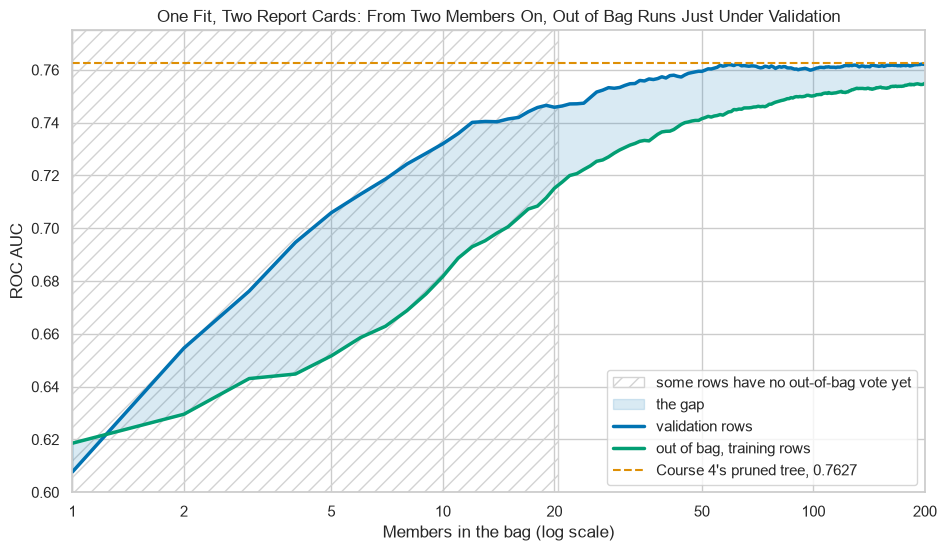

In [29]:
# two report cards from one fit: validation and out of bag by number of members, the gap shaded
fig, ax = plt.subplots(figsize=(11, 6))
# hatch="//" fills the band with diagonal lines in place of a colour
ax.axvspan(1, 20.5, facecolor="none", hatch="//", edgecolor="lightgray", label="some rows have no out-of-bag vote yet")
ax.fill_between(trees, oob_curve, curve, color="C0", alpha=0.15, label="the gap")
ax.plot(trees, curve, color="C0", linewidth=2.5, label="validation rows")
ax.plot(trees, oob_curve, color="C2", linewidth=2.5, label="out of bag, training rows")
ax.axhline(pruned_auc, color="C1", linestyle="--", label=f"Course 4's pruned tree, {pruned_auc:.4f}")
ax.set_xscale("log")
ax.set(xticks=[1, 2, 5, 10, 20, 50, 100, 200], xticklabels=[1, 2, 5, 10, 20, 50, 100, 200])
ax.set(xlim=(1, 200), ylim=(0.6, 0.775), xlabel="Members in the bag (log scale)", ylabel="ROC AUC")
ax.set_title("One Fit, Two Report Cards: From Two Members On, Out of Bag Runs Just Under Validation")
ax.legend(loc="lower right")
plt.show()

### Interpretation of the Out-of-Bag Score

It is scored on training rows, each by members that never saw it, so it costs no rows and no second fit.

It runs low while the bag is small: each row is scored only by the members that left it out, about 9 of 25, and the validation curve shows that fewer members rank worse.

The gap shrinks from 0.0259 at 25 members to 0.0072 at 200.

By 200 members a row's 74 or so voters rank almost as well as 200 do on the flat part of the validation curve, so most of what is left is the two different sets of rows.

**From two members on, the out-of-bag ROC AUC runs just under the validation curve, from the training rows alone. scikit-learn also keeps a score of its own.**

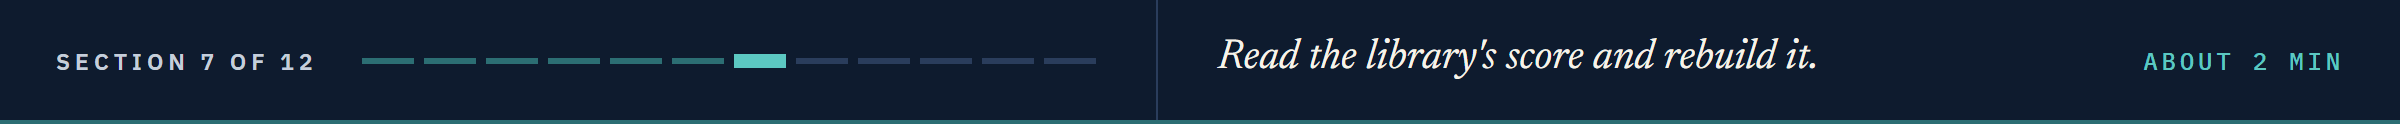

# The Library's Own Score

**Predict 3**

`bag.oob_score_` is the one out-of-bag number scikit-learn keeps for a bag.

Q. What is it for `bag`? Write down a number.

## Reading It

In [30]:
# scikit-learn's own out-of-bag score
print("oob_score_:", round(bag.oob_score_, 4))

oob_score_: 0.8113


Not the 0.7549 we computed.

## Rebuilding It

In [31]:
# accuracy of the out-of-bag output flagged above 0.5, and of flagging nobody
oob_flags = (oob_output > 0.5).astype(int)
print("Accuracy of the out-of-bag flags above 0.5:", round(accuracy_score(y_train, oob_flags), 4))
print("Accuracy of flagging nobody:", round(1 - y_train.mean(), 4))
print("Rows exactly at 0.5:", (oob_output == 0.5).sum(), " Accuracy at 0.5 or above:",
      round(accuracy_score(y_train, (oob_output >= 0.5).astype(int)), 4))

Accuracy of the out-of-bag flags above 0.5: 0.8113
Accuracy of flagging nobody: 0.7788
Rows exactly at 0.5: 46  Accuracy at 0.5 or above: 0.8114


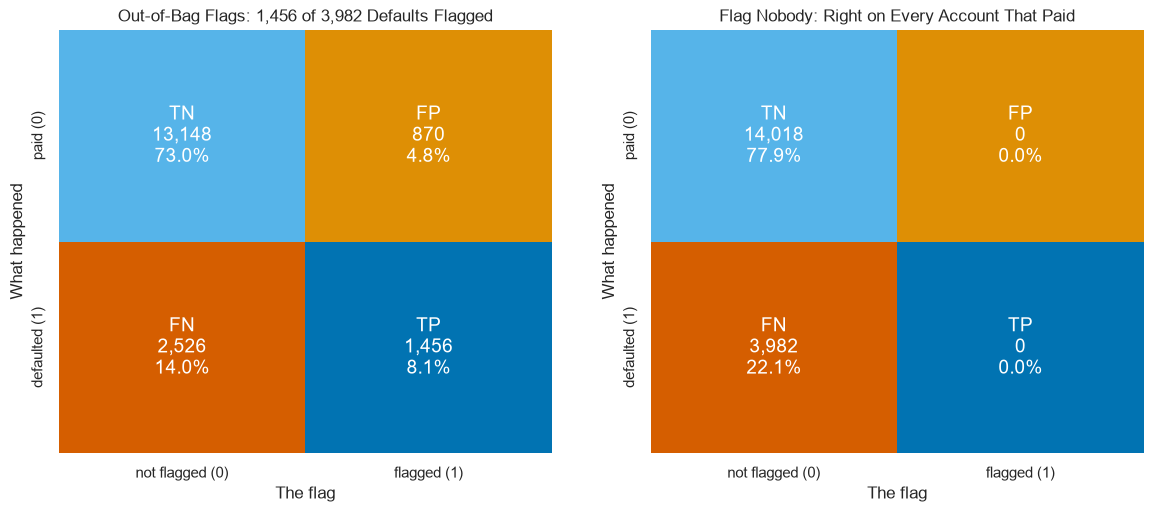

In [32]:
# the out-of-bag flags beside a model that flags nobody, on the training rows
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
draw_confusion(y_train, oob_flags, left, "Out-of-Bag Flags: 1,456 of 3,982 Defaults Flagged")
draw_confusion(y_train, np.zeros(len(y_train), dtype=int), right, "Flag Nobody: Right on Every Account That Paid")
plt.show()

### Interpretation of the Library's Score

`oob_score_` is the accuracy of the out-of-bag flags, with a row at exactly 0.5 counted as no default.

Flagging nobody is right on 77.88 percent of the training rows, so 0.8113 is 3.25 points above a model that reads nothing.

A ROC AUC's no-skill mark is 0.5 and this accuracy's is 0.7788, so the two are never set side by side.

**`oob_score_` is accuracy. This course reads `roc_auc_score` on `oob_decision_function_`.**

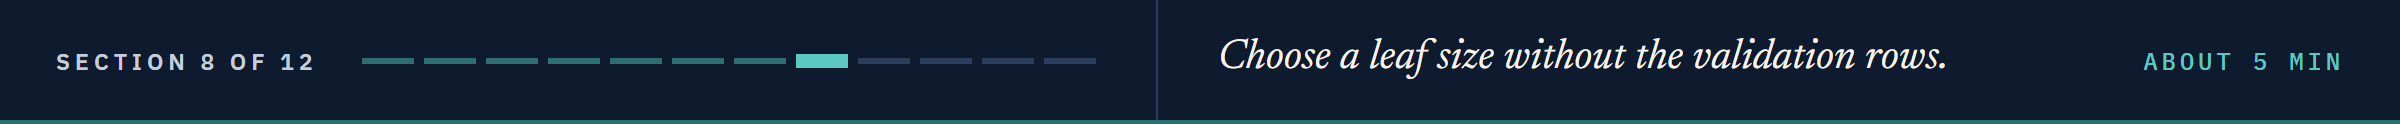

# Choosing Settings Out of Bag

## Out of Bag Against Five Folds

Is one out-of-bag score as good as cross-validation?
A test on the first 2,000 training rows, where five folds take seconds.

In [33]:
# the first 2,000 training rows: 100 full trees, fitted once, out-of-bag output kept
X_small, y_small = X_train.iloc[:2000], y_train.iloc[:2000]
small_bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=100, oob_score=True,
                              random_state=SEED, n_jobs=1).fit(X_small, y_small)
small_oob = roc_auc_score(y_small, small_bag.oob_decision_function_[:, 1])
print("Defaults:", y_small.sum(), " Out-of-bag ROC AUC:", round(small_oob, 4))

Defaults: 415  Out-of-bag ROC AUC: 0.7325


In [34]:
# the same bag scored by five stratified folds (Course 4's Day 5): five fits, each on four fifths of the 2,000 rows
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_scores = cross_val_score(small_bag, X_small, y_small, cv=folds, scoring="roc_auc", n_jobs=1)
print("Folds:", fold_scores.round(4), " Mean:", round(fold_scores.mean(), 4), " Sd:", round(fold_scores.std(), 4))

Folds: [0.7153 0.7385 0.746  0.6994 0.763 ]  Mean: 0.7325  Sd: 0.0225


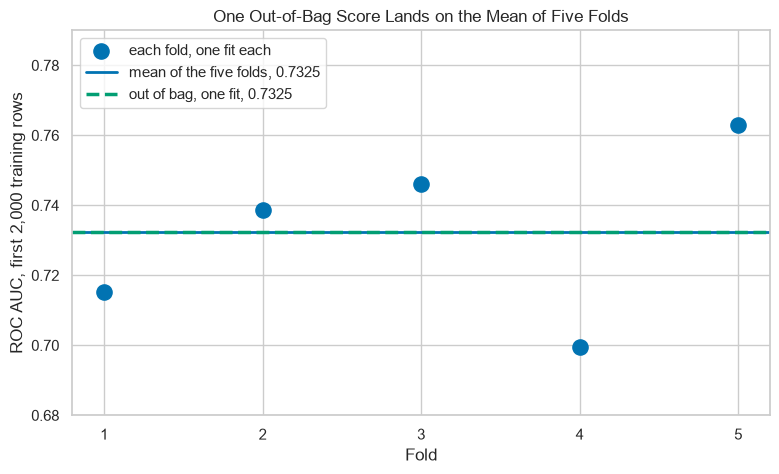

In [35]:
# the five folds as dots and their mean as a line, beside the one out-of-bag score as a dashed line
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(range(1, 6), fold_scores, s=120, color="C0", zorder=3, label="each fold, one fit each")
ax.axhline(fold_scores.mean(), color="C0", linewidth=2, label=f"mean of the five folds, {fold_scores.mean():.4f}")
ax.axhline(small_oob, color="C2", linestyle="--", linewidth=2.5, label=f"out of bag, one fit, {small_oob:.4f}")
ax.set(xticks=range(1, 6), ylim=(0.68, 0.79), xlabel="Fold", ylabel="ROC AUC, first 2,000 training rows")
ax.set_title("One Out-of-Bag Score Lands on the Mean of Five Folds")
ax.legend(loc="upper left")
plt.show()

The out-of-bag score and the five-fold mean agree to four decimals here.

The folds alone range over six hundredths, so a match this close is partly luck.

**On a bag, one out-of-bag score stands in for five folds, from one fit instead of five.**

## The Settings That Shape the Members

`.get_params()` lists a model's settings; `deep=False` leaves out the member's own.

In [36]:
# the bag's own settings, as `bag` has them
bag.get_params(deep=False)

{'bootstrap': True,
 'bootstrap_features': False,
 'estimator': DecisionTreeClassifier(random_state=42),
 'max_features': 1.0,
 'max_samples': None,
 'n_estimators': 200,
 'n_jobs': 1,
 'oob_score': True,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

`n_estimators`: the number of members.

`max_samples`: the rows each member draws, all of them by default (None or 1.0).

`bootstrap`: draw with replacement, as here, or without.

`oob_score`: keep the out-of-bag output.

`estimator`: the member, with its own settings, such as Course 4's Day 9 tree settings `max_depth`, `min_samples_leaf` and `class_weight`.

`min_samples_leaf` is the fewest training rows a leaf may hold, so larger leaves make each tree smaller and steadier.

**Predict 4**

A 100-member bag is fitted at each `min_samples_leaf` from 1 to 300.

Q. Sketch its out-of-bag ROC AUC against the leaf size: where does it peak, and what happens after?

## Sweeping the Leaf Size

In [37]:
# for each leaf size: a 100-member bag fitted once, scored on its training rows, out of bag, and on validation rows
leaf_sizes = [1, 3, 10, 30, 100, 300]
sweep = []
for leaf in leaf_sizes:
    leaf_bag = BaggingClassifier(estimator=DecisionTreeClassifier(min_samples_leaf=leaf, random_state=SEED), n_estimators=100,
                                 oob_score=True, random_state=SEED, n_jobs=1).fit(X_train, y_train)
    sweep.append([roc_auc_score(y_train, leaf_bag.predict_proba(X_train)[:, 1]),
                  roc_auc_score(y_train, leaf_bag.oob_decision_function_[:, 1]),
                  roc_auc_score(y_valid, leaf_bag.predict_proba(X_valid)[:, 1])])
sweep = pd.DataFrame(sweep, index=leaf_sizes, columns=["training", "out of bag", "validation"])
sweep

,training,out of bag,validation
1,0.9995,0.7502,0.7602
3,0.9946,0.7585,0.7700
10,0.9450,0.7731,0.7781
30,0.8810,0.7800,0.7832
100,0.8254,0.7818,0.7837
300,0.7962,0.7792,0.7780


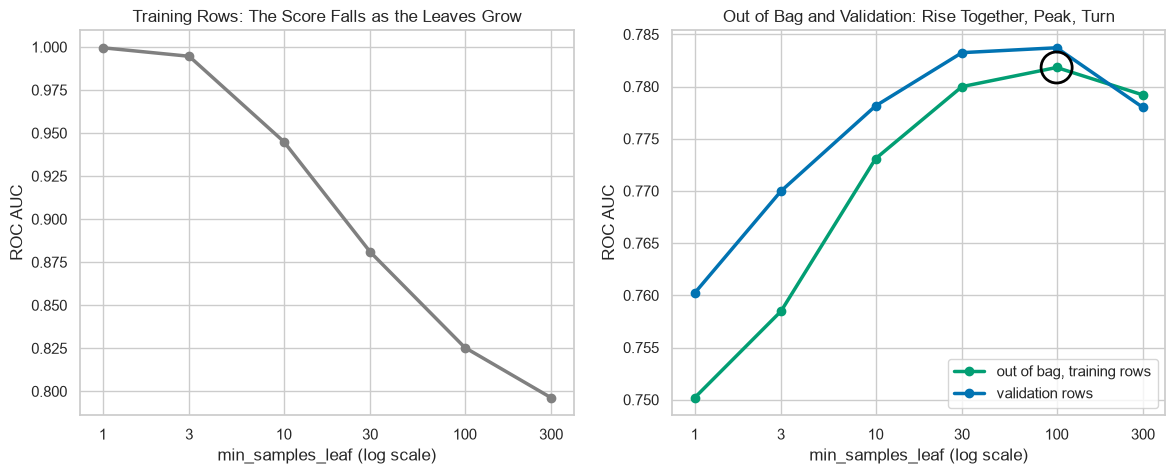

In [38]:
# the training score on the left; out of bag and validation on the right, the out-of-bag top circled; log axes
best_leaf = sweep["out of bag"].idxmax()
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5))
left.plot(sweep.index, sweep["training"], marker="o", linewidth=2.5, color="gray")
left.set(xscale="log", xticks=leaf_sizes, xticklabels=leaf_sizes, xlabel="min_samples_leaf (log scale)", ylabel="ROC AUC", title="Training Rows: The Score Falls as the Leaves Grow")
right.plot(sweep.index, sweep["out of bag"], marker="o", linewidth=2.5, color="C2", label="out of bag, training rows")
right.plot(sweep.index, sweep["validation"], marker="o", linewidth=2.5, color="C0", label="validation rows")
right.scatter(best_leaf, sweep.loc[best_leaf, "out of bag"], s=500, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
right.set(xscale="log", xticks=leaf_sizes, xticklabels=leaf_sizes, xlabel="min_samples_leaf (log scale)", ylabel="ROC AUC", title="Out of Bag and Validation: Rise Together, Peak, Turn")
right.legend(loc="lower right")
plt.show()

The training score falls from near 1 as the leaves grow: the trees memorise less.

Out of bag and validation rise together to a top at the same leaf size, then both turn down.

The out-of-bag line sits under validation up to 100-row leaves and edges just above it at 300.

## The Chosen Bag on the Validation Rows

In [39]:
# the leaf size the out-of-bag score chose, refitted, and scored once on the validation rows
chosen_bag = BaggingClassifier(estimator=DecisionTreeClassifier(min_samples_leaf=best_leaf, random_state=SEED), n_estimators=100,
                               oob_score=True, random_state=SEED, n_jobs=1).fit(X_train, y_train)
chosen_valid = chosen_bag.predict_proba(X_valid)[:, 1]
print("Chosen min_samples_leaf:", best_leaf, " Validation ROC AUC:", round(roc_auc_score(y_valid, chosen_valid), 4),
      " Average precision:", round(average_precision_score(y_valid, chosen_valid), 4))
print("Above Course 4's pruned tree by", round(roc_auc_score(y_valid, chosen_valid) - pruned_auc, 4),
      "and its logistic regression by", round(roc_auc_score(y_valid, chosen_valid) - logit_auc, 4))

Chosen min_samples_leaf: 100  Validation ROC AUC: 0.7837  Average precision: 0.5573
Above Course 4's pruned tree by 0.021 and its logistic regression by 0.0647


**Chosen inside the training rows, reported on validation rows: a bag past Course 4's best, and no validation row helped choose it.**

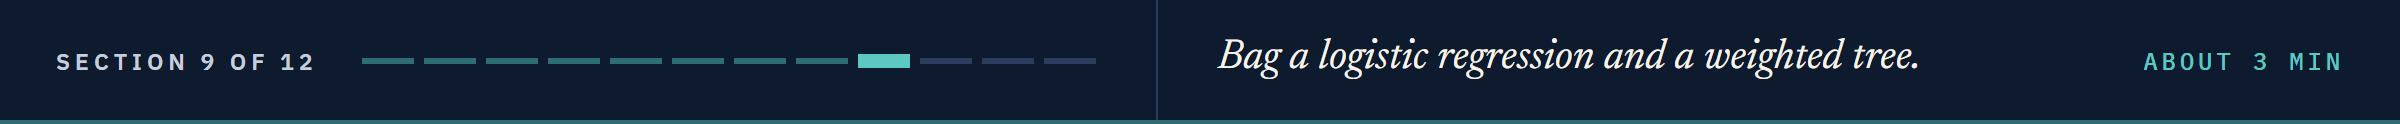

# Bagging Other Models

## Bagging a Logistic Regression

In [40]:
# 25 bootstrap copies of Course 4's logistic pipeline, averaged
bag_logit = BaggingClassifier(estimator=Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]),
                              n_estimators=25, random_state=SEED, n_jobs=1).fit(X_train, y_train)
logit_valid = logit.predict_proba(X_valid)[:, 1]
bag_logit_valid = bag_logit.predict_proba(X_valid)[:, 1]
print("ROC AUC alone:", round(logit_auc, 4), " Bagged:", round(roc_auc_score(y_valid, bag_logit_valid), 4))
print("Mean move per account:", round(np.abs(bag_logit_valid - logit_valid).mean(), 4))

ROC AUC alone: 0.719  Bagged: 0.7195
Mean move per account: 0.002


In [41]:
# how far an account's member outputs spread: logistic copies against the 200 full trees
logit_members = np.column_stack([m.predict_proba(X_valid.to_numpy())[:, 1] for m in bag_logit.estimators_])
print("Mean spread, logistic copies:", round(logit_members.std(axis=1).mean(), 4),
      " full trees:", round(outputs.std(axis=1).mean(), 4))

Mean spread, logistic copies: 0.0121  full trees: 0.3396


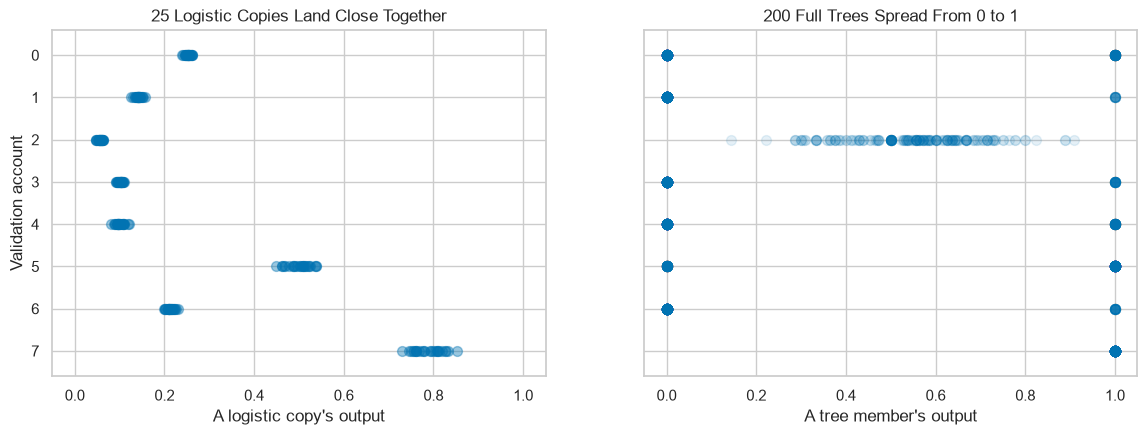

In [42]:
# the members' outputs for the first eight validation accounts: 25 logistic copies, then 200 full trees
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for account in range(8):
    left.scatter(logit_members[account], [account] * 25, s=50, alpha=0.4, color="C0")
    right.scatter(outputs[account], [account] * 200, s=50, alpha=0.1, color="C0")
left.set(xlim=(-0.05, 1.05), ylim=(7.6, -0.6), xlabel="A logistic copy's output", ylabel="Validation account")
right.set(xlim=(-0.05, 1.05), xlabel="A tree member's output")
left.set_title("25 Logistic Copies Land Close Together")
right.set_title("200 Full Trees Spread From 0 to 1")
plt.show()

A logistic regression hardly moves with its sample, so its copies agree and their average is the model alone.

Bagging cancels the part of each member that comes from its sample's luck: a tree has plenty, a logistic regression almost none.

## A Weighted Tree Inside the Bag

The tree inside a bag carries its own settings, Course 4's Day 9 class weights included.

In [43]:
# the chosen bag again, its trees weighting the defaults as Course 4's Day 9 did
weighted_bag = BaggingClassifier(estimator=DecisionTreeClassifier(min_samples_leaf=best_leaf, class_weight="balanced", random_state=SEED),
                                 n_estimators=100, oob_score=True, random_state=SEED, n_jobs=1).fit(X_train, y_train)
weighted_valid = weighted_bag.predict_proba(X_valid)[:, 1]
print("ROC AUC, weighted:", round(roc_auc_score(y_valid, weighted_valid), 4), " unweighted:", round(roc_auc_score(y_valid, chosen_valid), 4))
print("Flagged at 0.5, weighted:", (weighted_valid >= 0.5).sum(), " unweighted:", (chosen_valid >= 0.5).sum())
print("Mean output, weighted:", round(weighted_valid.mean(), 4), " Default rate:", round(y_valid.mean(), 4))

ROC AUC, weighted: 0.7796  unweighted: 0.7837
Flagged at 0.5, weighted: 1688  unweighted: 654
Mean output, weighted: 0.4129  Default rate: 0.2212


The weights barely move the ranking, and they more than double the accounts flagged at 0.5.

The weighted bag's mean output sits far above the default rate, so it is the model's score, not a default rate.

**Bagging helps a model that moves with its sample; the tree inside carries its own settings, weights included.**

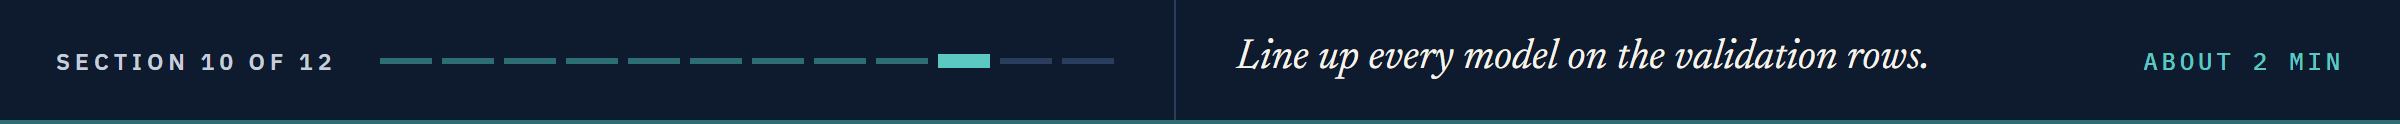

# Model Performance Comparison

## Validation Rows, Every Model

In [44]:
# every model's row on the validation rows, then average precision, and the out-of-bag ROC AUC where a bag kept one
models = {"Course 4 full tree": full_tree, "Course 4 pruned tree": pruned_tree, "Course 4 logistic": logit,
          "bag of 10": bag10, "bag of 200": bag, "chosen bag": chosen_bag, "bagged logistic": bag_logit, "weighted bag": weighted_bag}
comparison = pd.concat([model_performance_classification(m, X_valid, y_valid) for m in models.values()])
comparison.index = list(models)
comparison["Average precision"] = [average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in models.values()]
oob_scores = {name: roc_auc_score(y_train, models[name].oob_decision_function_[:, 1]) for name in ["bag of 200", "chosen bag", "weighted bag"]}
comparison["Out-of-bag ROC AUC"] = pd.Series(oob_scores)
comparison

,ROC AUC,Accuracy,Recall,Precision,F1,Average precision,Out-of-bag ROC AUC
Course 4 full tree,0.6161,0.7278,0.4032,0.3888,0.3959,0.2917,NaN
Course 4 pruned tree,0.7627,0.7683,0.5840,0.4805,0.5272,0.4954,NaN
Course 4 logistic,0.7190,0.8123,0.2442,0.7248,0.3653,0.4946,NaN
bag of 10,0.7320,0.7943,0.4069,0.5471,0.4667,0.4584,NaN
bag of 200,0.7621,0.8165,0.3760,0.6464,0.4755,0.5110,0.7549
chosen bag,0.7837,0.8202,0.3399,0.6896,0.4553,0.5573,0.7818
bagged logistic,0.7195,0.8117,0.2411,0.7223,0.3616,0.4952,NaN
weighted bag,0.7796,0.7692,0.6142,0.4828,0.5406,0.5543,0.7803


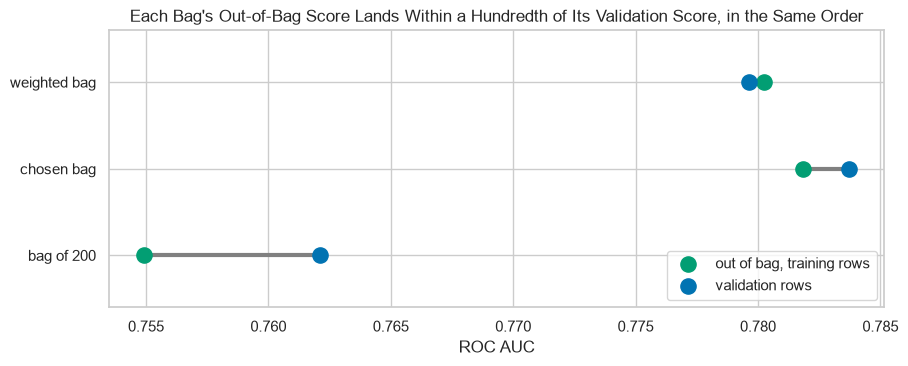

In [45]:
# out of bag against validation ROC AUC for each bag that kept an out-of-bag output
bags = comparison.dropna()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hlines(bags.index, bags["Out-of-bag ROC AUC"], bags["ROC AUC"], color="gray", linewidth=3)
ax.scatter(bags["Out-of-bag ROC AUC"], bags.index, s=120, color="C2", label="out of bag, training rows", zorder=3)
ax.scatter(bags["ROC AUC"], bags.index, s=120, color="C0", label="validation rows", zorder=3)
ax.set(xlabel="ROC AUC", ylim=(-0.6, 2.6))
ax.set_title("Each Bag's Out-of-Bag Score Lands Within a Hundredth of Its Validation Score, in the Same Order")
ax.legend(loc="lower right")
plt.show()

The chosen bag has the highest ROC AUC and average precision of the eight.

Accuracy, recall and precision depend on the 0.5 threshold: the weighted bag flags far more and so has the highest recall.

The three out-of-bag scores rank the bags as their validation scores do; with 100-row leaves the gap is under 0.002 either way.

**One bag, chosen out of bag, leads. Every bag still asks its trees the same thing first.**

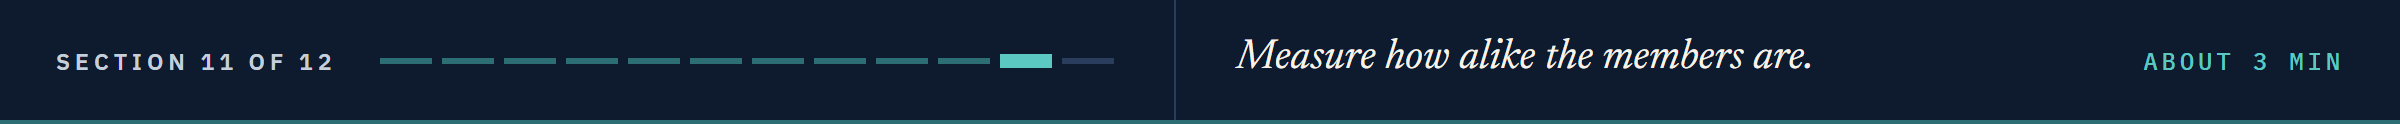

# What Bagging Cannot Fix

## The Same First Question

In [46]:
# the root question of each of the 200 members, as text, counted
roots = pd.Series([FEATURES[tree.tree_.feature[0]] + " <= " + str(round(tree.tree_.threshold[0], 1)) for tree in bag.estimators_])
roots.value_counts()

PAY_0 <= 1.5    199
PAY_0 <= 0.5      1
Name: count, dtype: int64

Every sample holds the same pattern in `PAY_0`, so nearly every member asks it first, as Day 1's ten trees did.

## How Alike Two Members Are

The **member correlation** of two members is the correlation of their outputs on the 6,000 validation rows.
`np.corrcoef` treats each row of a table as one variable, so we pass the outputs turned on their side, a row per member.
`np.triu_indices(200, k=1)` gives the positions above the diagonal of a 200 by 200 table: each pair of members once.

In [47]:
# the member correlation of every pair of the 200 members
pair_corr = np.corrcoef(outputs.T)[np.triu_indices(200, k=1)]
print(len(pair_corr), "pairs  Mean:", round(pair_corr.mean(), 4), " Lowest:", round(pair_corr.min(), 3), " Highest:", round(pair_corr.max(), 3))

19900 pairs  Mean: 0.2567  Lowest: 0.198  Highest: 0.318


A **rug** draws a short tick on the axis for every value, under a smoothed density curve.

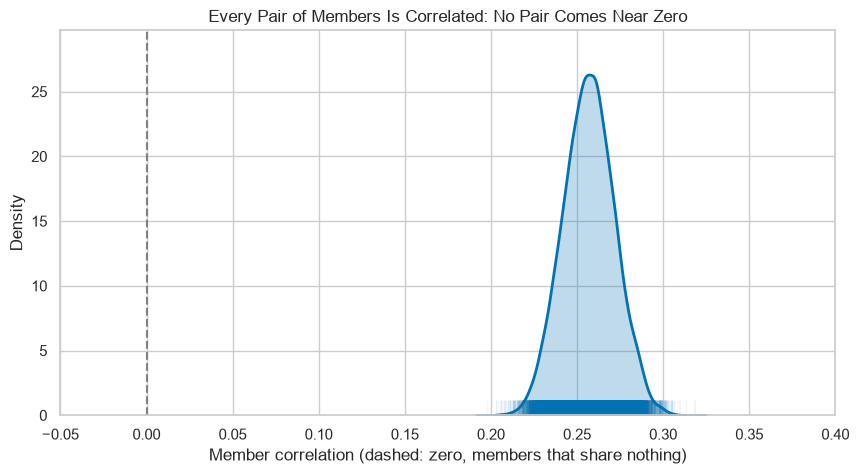

In [48]:
# the 19,900 member correlations as a density curve, with a rug of ticks along the axis
fig, ax = plt.subplots()
sns.kdeplot(pair_corr, fill=True, linewidth=2, ax=ax)
sns.rugplot(pair_corr, height=0.04, alpha=0.05, ax=ax)
ax.axvline(0, color="gray", linestyle="--")
ax.set(xlim=(-0.05, 0.4), xlabel="Member correlation (dashed: zero, members that share nothing)", ylabel="Density")
ax.set_title("Every Pair of Members Is Correlated: No Pair Comes Near Zero")
plt.show()

The member correlation runs from about 0.2 to 0.3 and averages 0.2567.

The part the members share is the same in every member, so averaging more of them cannot remove it.

**To gain more, the members must disagree more without getting weaker. Day 3 trades some of each tree's strength for disagreement.**

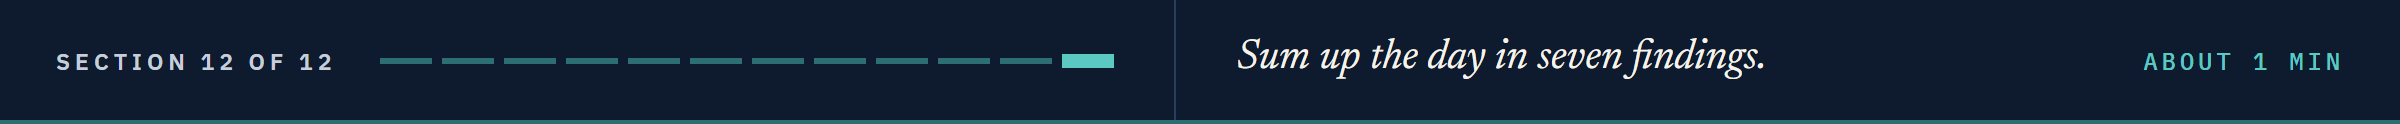

# Insights and Conclusion

A bag's output is the plain average of its members.

About 50 full trees do most of the work, and 200 sit just under Course 4's pruned tree.

The out-of-bag ROC AUC tracks the validation score from just under it, from the training rows alone, and matched five folds on 2,000 rows.

`oob_score_` is accuracy, not ROC AUC.

A leaf size chosen out of bag passed Course 4's best on the validation rows.

Bagging barely moves a logistic regression.

The members share their first question, and their outputs stay correlated.

**Day 3 makes the trees disagree on purpose.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit a `BaggingClassifier` and check its output against the average of its members.
* Watch an account's running average and the bag's score as members are added.
* Find each training row's out-of-bag output and score it, by hand and with `oob_decision_function_`.
* Say what `oob_score_` measures, and compare an out-of-bag score with five folds.
* Choose a member's setting out of bag, report it on validation rows, and bag a model other than a tree.
* Measure how alike a bag's members are.

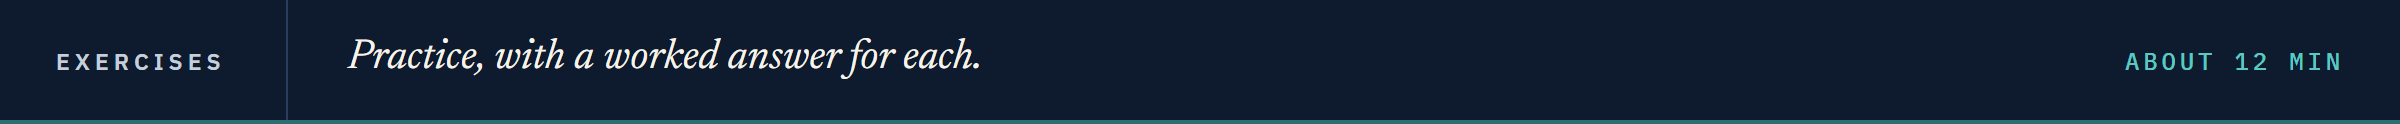

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [49]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Half-Size Samples**

Q. Fit a bag of 100 full trees with `max_samples=0.5`, so each member draws 9,000 rows, and `oob_score=True`. Store its validation ROC AUC in `ex1_valid` and its out-of-bag ROC AUC in `ex1_oob`.

In [50]:
# your code here
ex1_valid = ...
ex1_oob = ...

In [51]:
check("Exercise 1 the validation ROC AUC", ex1_valid, 0.7673487370165574)
check("Exercise 1 the out-of-bag ROC AUC", ex1_oob, 0.7570185556075244)

Exercise 1 the validation ROC AUC: not attempted yet
Exercise 1 the out-of-bag ROC AUC: not attempted yet


### Exercise 2

**The Gap at 25 Members**

Q. Fit a bag of 25 full trees with `oob_score=True`. Store its validation ROC AUC minus its out-of-bag ROC AUC in `ex2_gap25`, and the same gap for `bag` in `ex2_gap200`.

In [52]:
# your code here
ex2_gap25 = ...
ex2_gap200 = ...

In [53]:
check("Exercise 2 the gap at 25 members", ex2_gap25, 0.025864290435551274)
check("Exercise 2 the gap at 200 members", ex2_gap200, 0.007160685735726258)

Exercise 2 the gap at 25 members: not attempted yet
Exercise 2 the gap at 200 members: not attempted yet


### Exercise 3

**A Function for Out-of-Bag Coverage**

Q. Write `oob_coverage(model, n_rows)` that returns the share of the `n_rows` training rows left out by at least one member, from `model.estimators_samples_`. Store `oob_coverage(bag10, len(X_train))` in `ex3_coverage`.

In [54]:
# your code here
ex3_coverage = ...

In [55]:
check("Exercise 3 the ten-tree bag's coverage", ex3_coverage, 0.9896666666666667)

Exercise 3 the ten-tree bag's coverage: not attempted yet


### Exercise 4: AI check

**The Report That Mislabelled Its Score**

You asked an AI assistant for a function that reports a bag's out-of-bag ROC AUC.
This came back.
It runs, and it returns a number between 0 and 1.
Test it, then find the one bug.

In [56]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def oob_report(model, target):
    # the bag's out-of-bag ROC AUC on the training rows it was fitted on, and its number of members
    return {"oob_roc_auc": model.oob_score_, "members": len(model.estimators_)}

ai_report = oob_report(bag, y_train)
print(ai_report)

{'oob_roc_auc': 0.8113333333333334, 'members': 200}


In [57]:
# the test: the reported ROC AUC must be the ROC AUC of the bag's out-of-bag output
assert ai_report["oob_roc_auc"] == roc_auc_score(y_train, bag.oob_decision_function_[:, 1]), "oob_roc_auc is not a ROC AUC"

AssertionError: oob_roc_auc is not a ROC AUC

Q. Fix the function, and store `oob_report(chosen_bag, y_train)["oob_roc_auc"]` in `ex4_oob`.

In [58]:
# your code here
ex4_oob = ...

In [59]:
check("Exercise 4 the chosen bag's out-of-bag ROC AUC", ex4_oob, 0.7818272897176974)

Exercise 4 the chosen bag's out-of-bag ROC AUC: not attempted yet


## Congratulations!

You let scikit-learn bag 200 trees and proved its output is the plain average you took by hand on Day 1.
You watched each account's average settle and the bag's score flatten after about 50 members.
You scored the bag on rows its members never saw, caught the library's own score being something else, and chose a leaf size without touching the validation rows.
That bag passes Course 4's best, and no validation row helped choose it.
In Day 3 you make the trees disagree on purpose: the random forest.

[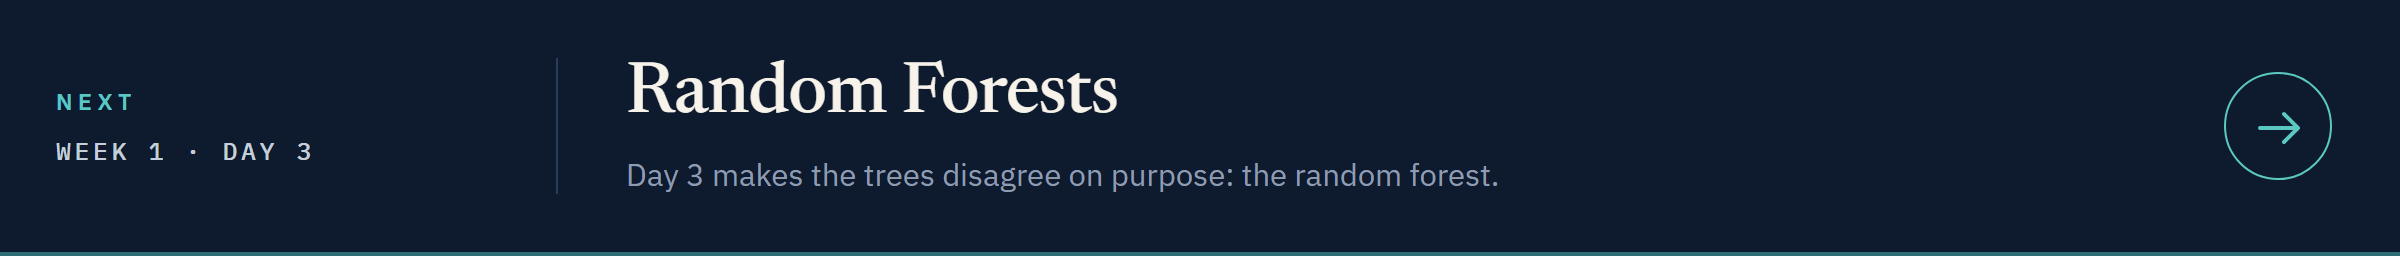](../day3/03_random_forests.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day3/03_random_forests.ipynb)